<a href="https://colab.research.google.com/github/vitor-thompson/physics-informed-neural-networks-pinn/blob/main/experiments/passo-02-oscilador-harmonico/passo-02-oscilador-harmonico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN — Experimento 02: Oscilador Harmônico Simples com PyTorch

---



## __Tabela de conteúdos__

<ol>
    <li><a href="#Objectives">Objetivos</a></li>
    <li>
        <a href="#Setup">Configuração</a>
        <ol>
            <li><a href="#Installing-Required-Libraries">Instalação das Bibliotecas Necessárias</a></li>
            <li><a href="#Importing-Required-Libraries">Importação das Bibliotecas Necessárias</a></li>
            <li><a href="#Device-Check-for-PyTorch">Verificação de Dispositivo para PyTorch</a></li>
        </ol>
    </li>
    <li>
        <a href="#Background">Contexto Teórico</a>
        <ol>
            <li><a href="#Physics-Informed-Neural-Networks-(PINNs)-Theory">Teoria das Redes Neurais Informadas por Física (PINNs)</a></li>
            <li><a href="#Thermal/Chemical-Diffusion-Theory-&amp;-Numerical-Solution">Oscilador Harmônico Simples (Massa-Mola sem Atrito)</a></li>
            <li><a href="#Why-PINNs?">Por que PINNs?</a></li>
        </ol>
    </li>
    <li>
        <a href="#The-Model">O Modelo</a>
        <ol>
            <li><a href="#The-Neural-Network">A Rede Neural</a></li>
            <li><a href="#The-Loss-Function">A Função de Perda Física (Loss) e Condições Iniciais</a></li>
            <li><a href="#Training">Treinamento</a></li>
        </ol>
    </li>
    <li>
        <a href="#Result">Resultado</a>
        <ol>
            <li><a href="#Comparing-to-Theoretical-Solution">Comparação com a Solução Teórica</a></li>
            <li><a href="#Visualizing-Training-Convergence">Visualização da Convergência do Treinamento</a></li>
        </ol>
    </li>
</ol>

## 1. Objetivos
Este experimento aplica uma Rede Neural Informada por Física (PINN) em PyTorch para resolver a equação diferencial ordinária (EDO) de 2ª ordem do Oscilador Harmônico Simples (sistema massa-mola sem atrito).O foco aqui é combinar:Ativação sinusoidal (SIREN), adequada para funções periódicas e oscilatórias.Condições iniciais exatas por construção (hard constraints) para posição $x(0) = x_0$ e velocidade $\left.\frac{dx}{dt}\right\vert{}_{t=0} = v_0$.Otimização com L-BFGS e validação contra a solução analítica exata.

----


## Configuração

Para este laboratório, você usará as seguintes bibliotecas:

*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para operações matemáticas.
*   [`PyTorch`](https://pytorch.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para aprendizado de máquina e funções relacionadas a pipelines de deep learning.
*   [`scipy`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para calcular a solução pelo método numérico tradicional.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) para ferramentas adicionais de plotagem gráfica.

### Instalação das bibliotecas necessárias

Antes de começarmos a construir nossa Rede Neural Informada por Física (PINN), precisamos garantir que todas as bibliotecas necessárias estejam instaladas. Esta etapa configurará o ambiente necessário para o laboratório, incluindo o `PyTorch` e outros pacotes essenciais.

In [ ]:
%pip install torch numpy matplotlib scipy

### Importação das bibliotecas necessárias

_Recomendamos que você importe todas as bibliotecas necessárias em um único lugar (aqui):_

In [ ]:
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
from scipy.special import erf

# You can also use this section to suppress warnings generated by your code:
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn
warnings.filterwarnings('ignore')

### Verificação de dispositivo para PyTorch

O `PyTorch` pode ser acelerado por GPU. Se você tiver uma GPU disponível em seu dispositivo local, você pode baixar este notebook e usar a GPU localmente.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Contexto Teórico

### Teoria das Redes Neurais Informadas por Física (PINNs)

As Redes Neurais Informadas por Física (PINNs) são uma abordagem inovadora que mescla as redes neurais tradicionais com princípios físicos para resolver problemas complexos.

O [Artigo científico sobre PINN](https://www.sciencedirect.com/science/article/abs/pii/S0021999118307125) foi publicado no *Journal of Computational Physics* em 2019.

Diferente das redes neurais convencionais que dependem exclusivamente de dados, **as PINNs incorporam as leis físicas subjacentes, como leis de conservação, condições de contorno e equações diferenciais, diretamente no processo de aprendizado**. Essa integração permite que o modelo seja mais preciso, confiável e interpretável, especialmente quando os dados são escassos ou ruidosos.

Em uma PINN, **a função de perda é aumentada com termos que representam os resíduos das equações diferenciais governantes**. Ao minimizar essa função de perda, a rede neural não apenas se ajusta aos dados, mas também satisfaz as leis físicas. Isso torna as PINNs particularmente poderosas para resolver problemas onde as equações governantes são bem conhecidas, como dinâmica de fluidos, transferência de calor e deformação de materiais.

### Oscilador Harmônico Simples (Massa-Mola sem Atrito)
O **Oscilador Harmônico Simples (Massa-Mola sem Atrito)** é descrito por uma equação diferencial ordinária (EDO) de 2ª ordem que modela o movimento oscilatório de uma massa presa a uma mola ideal, sem perda de energia por atrito ou amortecimento. A equação do movimento é expressa como:

$$m\frac{d^2x(t)}{dt^2} + kx(t) = 0 \implies \frac{d^2x(t)}{dt^2} + \omega_0^2 x(t) = 0, \quad \omega_0 = \sqrt{\frac{k}{m}}$$

Onde:
- $x(t)$ é a posição da massa em relação à posição de equilíbrio no instante de tempo $t$.
- $m$ é a massa do corpo (em $\text{kg}$).
- $k$ é a constante elástica da mola (em $\text{N/m}$).
- $\omega_0 = \sqrt{k/m}$ é a frequência angular natural de oscilação (em $\text{rad/s}$).

Neste laboratório, focamos em treinar uma PINN para aprender $x(t)$ respeitando a EDO e ambas as condições iniciais, comparando a trajetória prevista pela rede com a solução teórica exata. Métodos numéricos tradicionais, como Runge-Kutta ou Velocity Verlet, avançam no tempo por passos discretos, enquanto a PINN representa $x(t)$ como uma função contínua e diferenciável por todo o domínio temporal.

## Por que PINNs?

Embora os métodos numéricos tradicionais sejam eficazes para resolver EDPs, eles podem se tornar computacionalmente caros, **especialmente para problemas de alta dimensão ou geometrias complexas**. Além disso, esses métodos podem exigir um refinamento extensivo de malha e técnicas de estabilização para alcançar soluções precisas.

As Redes Neurais Informadas por Física oferecem uma alternativa poderosa ao incorporar as leis físicas diretamente na arquitetura da rede neural. **As PINNs podem lidar eficientemente com problemas que possuem condições de contorno complexas e domínios irregulares sem a necessidade de malhas extensivas ou discretização**. Além disso, elas podem ser **treinadas usando uma quantidade relativamente pequena de dados**, pois as leis físicas guiam o processo de aprendizado, garantindo que a solução seja fisicamente consistente e orientada por dados.

Ao usar PINNs para resolver a equação do **Oscilador Harmônico Simples (Massa-Mola sem Atrito)**, você ganha intuição prática sobre como a lei física pode ser embutida diretamente no treinamento da rede neural — e como essa mesma abordagem escala para problemas mais complexos.

Em comparação aos métodos numéricos tradicionais (que dependem de malhas ou passos discretos no tempo), as PINNs se destacam por:
- **Representação contínua e diferenciável:** a rede gera $x(t)$ de forma contínua em qualquer instante $t$ dentro do domínio treinado, permitindo avaliar posição, velocidade ($\frac{dx}{dt}$) e aceleração ($\frac{d^2x}{dt^2}$) via diferenciação automática.
- **Flexibilidade para condições e parâmetros:** a mesma formulação permite testar diferentes condições iniciais ($x_0$, $v_0$), frequências naturais ($\omega_0$) ou estender o modelo para sistemas com amortecimento, forças externas ou problemas inversos (estimar parâmetros físicos a partir de dados).
- **Base para sistemas mais complexos:** dominar uma EDO de 2ª ordem oscilatória prepara o terreno para sistemas acoplados, dinâmica não linear e equações diferenciais parciais (EDPs) em múltiplas dimensões.

## 4. O Modelo

### A Rede Neural e o Ansatz com Condições Iniciais Exatas
Nesta abordagem do **Passo 02 (Oscilador Harmônico Simples)**, combinamos duas melhorias importantes para sistemas oscilatórios:

- **Ativação Senoidal (`SinActivation` / `SirenPINN`):** em vez de usar apenas `Tanh`, a rede `SirenPINN` emprega ativações senoidais ($\sin$). Como a própria dinâmica do oscilador harmônico é periódica, ativações senoidais facilitam o aprendizado de oscilações contínuas ao longo do tempo.
- **Condições Iniciais por Construção (*Hard Constraints*):** em vez de depender apenas de termos de penalidade na função de perda para impor $x(0) = x_0$ e $\left.\frac{dx}{dt}\right|_{t=0} = v_0$, definimos a solução como uma função composta (*ansatz*):

$$x(t) = x_0 + v_0 t + \left(1 - e^{-t^2}\right)\text{NN}(t)$$

Em $t = 0$, o fator $\left(1 - e^{-t^2}\right)$ e sua derivada em relação a $t$ valem $0$. Com isso, $x(0) = x_0$ e $\left.\frac{dx}{dt}\right|_{t=0} = v_0$ são satisfeitos automaticamente por construção em qualquer etapa do treinamento.

In [ ]:
# Criamos a ativação Sinusoidal personalizada para o PyTorch
class SinActivation(nn.Module):
  def forward(self, x):
    return torch.sin(x)


# 1. Definimos uma rede usando ativação Sinusoidal (Siren), ideal para oscilações
class SirenPINN(nn.Module):
  def __init__(self):
    super(SirenPINN, self).__init__()
    self.net = nn.Sequential(
        nn.Linear(1, 64),
        SinActivation(),
        nn.Linear(64, 64),
        SinActivation(),
        nn.Linear(64, 64),
        SinActivation(),
        nn.Linear(64, 1),
    )

  def forward(self, t):
    return self.net(t)


# 2. Ansatz que satisfaz as condições iniciais por construção (Hard constraints)
# x(t) = x_0 + v_0 * t + (1 - e^(-t^2)) * NN(t)
def get_exact_pinn_prediction(model, t, x_0, v_0):
  nn_out = model(t)
  # Fator de transição suave que vale 0 em t=0 e cresce rapidamente
  factor = 1.0 - torch.exp(-(t**2))
  return x_0 + v_0 * t + factor * nn_out

### A Função de Perda Física (Loss)
Como o *ansatz* `get_exact_pinn_prediction` já impõe $x(0) = x_0$ e $\left.\frac{dx}{dt}\right|_{t=0} = v_0$ por construção, não precisamos mais somar parcelas de erro para as condições iniciais.

A função `exact_ic_pinn_loss` avalia $x_{\text{pred}}(t)$ em pontos de colocação $t_{\text{colloc}}$, calcula as derivadas $\frac{dx}{dt}$ e $\frac{d^2x}{dt^2}$ com `torch.autograd.grad` (`create_graph=True`) e minimiza apenas o erro quadrático médio do resíduo da EDO:

$$r(t) = \frac{d^2x}{dt^2} + \omega_0^2 x$$

Assim, toda a capacidade do otimizador fica concentrada em fazer a curva satisfazer a dinâmica do oscilador harmônico em todo o intervalo de tempo.

In [ ]:
# 3. Função de perda focada unicamente na EDO (já que as ICs são exatas)
def exact_ic_pinn_loss(model, t_colloc, x_0, v_0, omega_0=2.0):
  t_colloc = t_colloc.clone().detach().requires_grad_(True)

  # Previsão que respeita as ICs por construção
  x_pred = get_exact_pinn_prediction(model, t_colloc, x_0, v_0)

  # Derivadas automáticas
  dx_dt = torch.autograd.grad(
      x_pred,
      t_colloc,
      grad_outputs=torch.ones_like(x_pred),
      create_graph=True,
  )[0]
  d2x_dt2 = torch.autograd.grad(
      dx_dt,
      t_colloc,
      grad_outputs=torch.ones_like(dx_dt),
      create_graph=True,
  )[0]

  # Resíduo da EDO: d²x/dt² + omega_0^2 * x = 0
  ode_residual = d2x_dt2 + (omega_0**2) * x_pred
  return torch.mean(ode_residual**2)

### Treinamento com L-BFGS e Condições Iniciais Exatas
Neste treinamento, reinicializamos o modelo com `SirenPINN()` e utilizamos o otimizador `L-BFGS` (`line_search_fn="strong_wolfe"`), que faz ajustes quasi-Newton (de segunda ordem) muito precisos em problemas suaves de física.

A cada iteração (em `300` passos externos com `max_iter=50` internos), sorteamos novos pontos de colocação aleatórios `t_colloc` (`N_colloc = 1000`) em $[0, t_{\max}]$ e definimos a função `closure()` exigida pelo `L-BFGS` para zerar gradientes, calcular a perda e retropropagar o erro.

In [ ]:
def train(model, optimizer, epochs, t_max=10.0, x_0=1.0, v_0=0.0, omega_0=2.0):
  saved_models = {}
  epoch_saved = []
  loss_history = []

  for epoch in tqdm(range(epochs), desc="Training (Hard ICs)"):
    # Amostragem dinâmica de pontos de colocação no intervalo [0, t_max]
    N_colloc = 1000
    t_colloc = (torch.rand((N_colloc, 1), device=device) * t_max).requires_grad_(
        True
    )

    last_loss = None

    def closure():
      nonlocal last_loss
      optimizer.zero_grad()
      loss = exact_ic_pinn_loss(model, t_colloc, x_0, v_0, omega_0=omega_0)
      loss.backward()
      last_loss = loss.item()
      return loss

    optimizer.step(closure)

    loss_history.append(last_loss)
    saved_models[epoch + 1] = {
        param_name: tensor.cpu().clone()
        for param_name, tensor in model.state_dict().items()
    }
    epoch_saved.append(epoch + 1)

  return model, epoch_saved, saved_models, loss_history

Você pode configurar e treinar o modelo ajustando o número de passos externos (por exemplo, `10` iterações com `max_iter=50` no `L-BFGS`, ou mais iterações conforme a frequência $\omega_0$ e o intervalo de tempo escolhido), monitorando a perda ao longo do processo. Se você tiver uma GPU disponível no Colab ou localmente, o treinamento tende a rodar mais rápido e permite testar mais iterações para refinar a convergência.

Esse processo permite que a PINN aprenda uma solução que respeita a equação do movimento do oscilador harmônico e as duas condições iniciais (posição e velocidade em $t = 0$, impostas por construção no *ansatz*) sem depender de uma grande base de dados rotulados.

In [ ]:
# Parâmetros físicos do exemplo (massa-mola sem atrito)
m = 1.0  # massa (kg)
k = 4.0  # constante elástica da mola (N/m)
omega_0 = (k / m) ** 0.5  # frequência angular natural: sqrt(k/m) = 2.0 rad/s

x_0 = 1.0  # posição inicial em t = 0 (m)
v_0 = 0.0  # velocidade inicial em t = 0 (m/s)
t_max = 10.0  # intervalo de tempo [0, t_max] (s)

# Reinicializa o modelo
model = SirenPINN().to(device)

# 4. Otimizador L-BFGS de alta fidelidade
optimizer_lbfgs = optim.LBFGS(
    model.parameters(), lr=0.1, max_iter=50, line_search_fn="strong_wolfe"
)

print("Treinando a PINN com condições iniciais exatas por construção...")

saved_models = {}
epoch_saved = []
loss_history = []

for epoch in tqdm(range(10), desc="Training (Hard ICs)"):
  # Pontos de colocação dinâmicos
  N_colloc = 1000
  t_colloc = (torch.rand((N_colloc, 1), device=device) * t_max).requires_grad_(
      True
  )

  last_loss = None

  def closure():
    global last_loss
    optimizer_lbfgs.zero_grad()
    loss = exact_ic_pinn_loss(model, t_colloc, x_0, v_0, omega_0=omega_0)
    loss.backward()
    last_loss = loss.item()
    return loss

  optimizer_lbfgs.step(closure)

  loss_history.append(last_loss)
  saved_models[epoch + 1] = {
      param_name: tensor.cpu().clone()
      for param_name, tensor in model.state_dict().items()
  }
  epoch_saved.append(epoch + 1)

Treinando a PINN com condições iniciais exatas por construção...


Training (Hard ICs): 100%|██████████| 10/10 [00:08<00:00,  1.15it/s]


## Resultado

### Comparação com a Solução Teórica

### 5.1. Comparação com a Solução Teórica (Hard ICs + SIREN)
Com o modelo treinado, avaliamos a previsão gerada por `get_exact_pinn_prediction` em uma malha de `300` pontos no intervalo $[0, t_{\max}]$ e comparamos diretamente com a solução analítica:

$$x(t) = x_0 \cos(\omega_0 t) + \frac{v_0}{\omega_0}\sin(\omega_0 t)$$

destacando o ponto inicial exato em $t = 0$.

In [ ]:
def plot_all_solutions(model, t_max=10.0, x_0=1.0, v_0=0.0, omega_0=2.0):
  # Pontos no tempo para visualização contínua
  t_plot_np = np.linspace(0.0, t_max, 300)
  t_plot_tensor = torch.tensor(
      t_plot_np, dtype=torch.float32, device=device
  ).unsqueeze(1)

  # Solução analítica (teórica)
  x_analytical = x_0 * np.cos(omega_0 * t_plot_np) + (v_0 / omega_0) * np.sin(
      omega_0 * t_plot_np
  )

  # Previsão contínua da PINN com condições iniciais exatas
  model.eval()
  with torch.no_grad():
    x_pinn_pred = (
        get_exact_pinn_prediction(model, t_plot_tensor, x_0, v_0)
        .cpu()
        .numpy()
        .squeeze()
    )

  # Gráfico comparativo contínuo
  plt.figure(figsize=(10, 5), dpi=100)
  plt.plot(
      t_plot_np,
      x_analytical,
      "tab:blue",
      linewidth=2.5,
      label="Solução Teórica (Oscilador Harmônico Simples)",
  )
  plt.plot(
      t_plot_np,
      x_pinn_pred,
      "tab:orange",
      linestyle="--",
      linewidth=2,
      label="PINN (Previsão contínua)",
  )

  # Instantes específicos para comparação discreta
  sampled_times_np = np.linspace(0.0, t_max, 5)
  sampled_times_tensor = torch.tensor(
      sampled_times_np, dtype=torch.float32, device=device
  ).unsqueeze(1)

  x_sampled_analytical = x_0 * np.cos(omega_0 * sampled_times_np) + (
      v_0 / omega_0
  ) * np.sin(omega_0 * sampled_times_np)
  with torch.no_grad():
    x_sampled_pinn = (
        get_exact_pinn_prediction(model, sampled_times_tensor, x_0, v_0)
        .cpu()
        .numpy()
        .squeeze()
    )

  plt.scatter(
      0.0,
      x_0,
      color="black",
      s=80,
      zorder=5,
      label=f"Posição inicial x(0) = {x_0:.2f} m",
  )
  plt.scatter(
      sampled_times_np,
      x_sampled_analytical,
      color="tab:blue",
      marker="o",
      s=50,
      zorder=4,
      label="Valores teóricos nos instantes",
  )
  plt.scatter(
      sampled_times_np,
      x_sampled_pinn,
      color="tab:orange",
      marker="x",
      s=60,
      zorder=4,
      label="Valores PINN nos instantes",
  )

  plt.title(
      "PINN vs. Solução Teórica — Oscilador Harmônico Simples (Sem Atrito)"
  )
  plt.xlabel("Tempo $t$ (s)")
  plt.ylabel("Posição $x(t)$ (m)")
  plt.grid(True, alpha=0.3)
  plt.legend(loc="lower right")
  plt.tight_layout()
  plt.show()

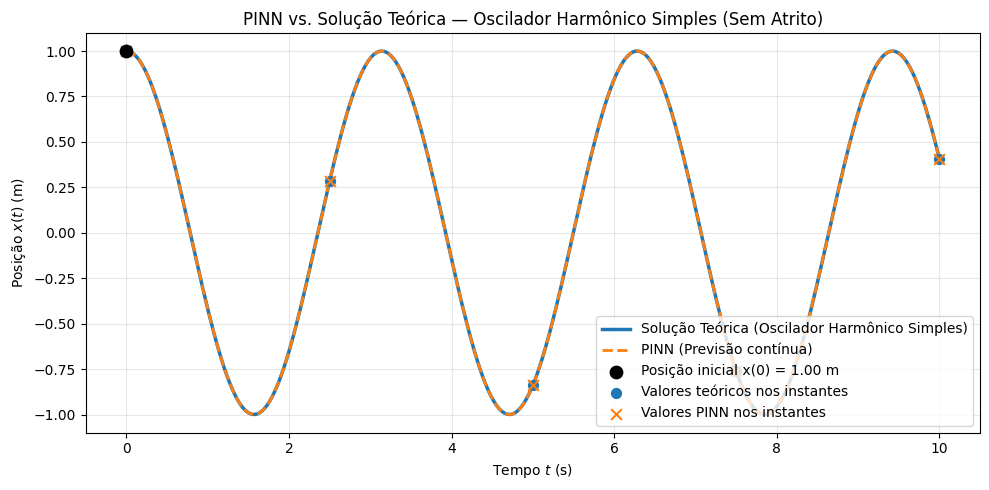

In [ ]:
# 1. Plotamos o resultado comparativo atualizado
plot_all_solutions(model, t_max=t_max, x_0=x_0, v_0=v_0, omega_0=omega_0)

Podemos ver que, apesar de pequenas diferenças, a PINN modelou com sucesso o oscilador harmônico simples ao longo do tempo, acompanhando bem tanto as condições iniciais de posição e velocidade em $t = 0$ quanto a oscilação periódica contínua sem perda de amplitude ao longo do intervalo.

### Visualização da Convergência do Treinamento

### Visualização da Convergência do Treinamento
Vamos visualizar como a previsão da PINN converge ao longo das épocas de treinamento, usando $t = 1{,}0\text{ s}$ (ou outro instante dentro de $[0, t_{\max}]$) como ponto de acompanhamento. Isso permite observar como a rede refina sua estimativa de posição $x(t)$ e se aproxima do valor analítico $x(1{,}0)$ à medida que o treinamento avança.

In [ ]:
def plot_epoch_comparison(
    epoch_saved, saved_models, device, t_max=10.0, x_0=1.0, v_0=0.0, omega_0=2.0
):
  fig, ax = plt.subplots(figsize=(7, 5), dpi=100)

  # Grade temporal para visualizar a curva inteira de x(t)
  t_np = np.linspace(0.0, t_max, 200)
  t_tensor = torch.tensor(
      t_np, dtype=torch.float32, device=device
  ).unsqueeze(1)

  # Solução teórica exata: x(t) = x_0 * cos(omega_0 * t) + (v_0 / omega_0) * sin(omega_0 * t)
  x_theoretical = x_0 * np.cos(omega_0 * t_np) + (v_0 / omega_0) * np.sin(
      omega_0 * t_np
  )

  ax.plot(
      t_np,
      x_theoretical,
      "k--",
      linewidth=2,
      label="Solução Teórica (Oscilador Harmônico Simples)",
  )
  (line,) = ax.plot([], [], "r-", linewidth=2, label="PINN Solution")

  # Amplitude máxima teórica para definir limites simétricos e fixos na animação
  amp_max = np.sqrt(x_0**2 + (v_0 / omega_0) ** 2)
  y_margin = max(0.25 * amp_max, 0.2)
  ax.set_xlim(0.0, t_max)
  ax.set_ylim(-(amp_max + y_margin), amp_max + y_margin)

  ax.set_title("PINN vs. Solução Teórica ao Longo das Épocas")
  ax.set_xlabel("Tempo $t$ (s)")
  ax.set_ylabel("Posição $x(t)$ (m)")
  ax.legend()
  ax.grid(True, alpha=0.3)

  temp_model = SirenPINN().to(device)
  temp_model.eval()

  def init():
    line.set_data([], [])
    return (line,)

  def update(epoch):
    temp_model.load_state_dict(
        {param: tensor.to(device) for param, tensor in saved_models[epoch].items()}
    )
    with torch.no_grad():
      x_pred = (
          get_exact_pinn_prediction(temp_model, t_tensor, x_0, v_0)
          .cpu()
          .numpy()
          .squeeze()
      )
    line.set_data(t_np, x_pred)
    ax.set_title(f"PINN vs. Solução Teórica — Época {epoch}")
    return (line,)

  ani = animation.FuncAnimation(
      fig,
      update,
      frames=epoch_saved,
      init_func=init,
      blit=False,
      interval=200,
  )

  plt.close(fig)
  return ani


ani = plot_epoch_comparison(
    epoch_saved, saved_models, device, t_max=t_max, x_0=x_0, v_0=v_0, omega_0=omega_0
)

In [ ]:
epoch_show = (list(range(1, 11)))
# Mantém apenas as épocas que existem em saved_models (evita KeyError)
epoch_show = [ep for ep in epoch_show if ep in saved_models]

anim = plot_epoch_comparison(
    epoch_show,
    saved_models,
    device,
    t_max=t_max,
    x_0=x_0,
    v_0=v_0,
    omega_0=omega_0,
)

In [ ]:
# Usage example
from IPython.display import HTML
HTML(anim.to_jshtml())

## Conclusão
Parabéns!

Neste **Experimento 02**, você aplicou uma Rede Neural Informada por Física (**PINN**) com ativação sinusoidal (`SirenPINN`), **condições iniciais exatas por construção (*hard constraints*)** e otimizador **L-BFGS** para resolver a equação diferencial ordinária de 2ª ordem do **Oscilador Harmônico Simples** (massa-mola sem atrito).

Em vez de depender de grandes volumes de dados rotulados ou de penalidades aproximadas para os valores iniciais em $t = 0$, a combinação do *ansatz* analítico com a minimização do resíduo da EDO via `autograd` permitiu acompanhar a oscilação periódica ao longo de todo o intervalo de tempo com alta fidelidade em relação à solução analítica.

### Próximos passos e aprofundamento
Os princípios vistos aqui — diferenciação automática, imposição de restrições físicas e escolha adequada de ativações e otimizadores — servem de base para problemas mais desafiadores, como:
- **Sistemas físicos mais ricos:** oscilador harmônico amortecido ou forçado, sistemas acoplados e problemas de maior dimensão.
- **Modelos de operadores neurais e arquiteturas modernas:** para quem deseja explorar aprendizado de operadores e modelos de sequência em física computacional, vale investigar abordagens como **Fourier Neural Operators (FNOs)**, **Graph Neural Networks (GNNs)** e arquiteturas baseadas em **Transformers** aplicadas a equações diferenciais.